<a href="https://colab.research.google.com/github/Yukiii0517/DissertationUCLY3/blob/main/Dissertation_Code_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The initial state is the pool has $x_0$ units of $X$ and $y_0$ units of $Y$: $x_0 y_0 = l_0^2$.

Typically, for intuitive understanding, we treat $X$ as the thing whose price is measured by $Y$, which is our numéraire (unit of account).

As an example, when $X$ is ETH and $Y$ is USDC, $P_0 = 2000$ means 1 ETH is worth 2000 USDC.

$q$ is measured in units of $X$, where $\theta_x = q$ means the trader takes out $Y$ and injects $X$, whereas $\theta_x = -q$ means the trader injects $Y$ and takes out $X$.

As an example, $\theta_x = q = 5$ means the trader injects 5 ETH and takes out the respective amount of USDC from the pool.

In [59]:
import numpy as np
import matplotlib.pyplot as plt

# 1) Define the Parameters (constants)
P0    = 2000.0          # pool price (typically how much USDC per ETH)
x0    = 10.0            # initial reserve of X(ETH) before our LP
q     = 5               # trade size
gamma = 0.997           # 1 - fee  (fee = 0.3%)

l0 = x0*np.sqrt(P0)     # initial liquidity


We optimise $\mathbb{E}[V(l)]$, the expected profit of a single LP providing
liquidity $l$, with respect to $l$. Writing $u = l + l_0$, the expected profit is
\begin{equation}
  \mathbb{E}[V(l)] = \frac{l}{l + l_0}\cdot\frac{G_a + G_b}{2},
\end{equation}
where $G_a$ and $G_b$ are the pool's gains from the trade (fee plus price impact)
in cases (a) and (b):
\begin{equation}
  G_a = P_0 q - \frac{\gamma P_0\, u\, q}{u + \gamma q\sqrt{P_0}},
  \qquad
  G_b = \frac{P_0\, u\, q}{\gamma\left(u - q\sqrt{P_0}\right)} - P_0 q .
\end{equation}

The FOC is
\begin{equation}
  l_0\,(G_a + G_b) + l\,(l + l_0)\left(\frac{\partial G_a}{\partial l}
  + \frac{\partial G_b}{\partial l}\right) = 0,
\end{equation}
where
\begin{equation}
  \frac{\partial G_a}{\partial l}
  = -\frac{\gamma^2 q^2 P_0^{3/2}}{\left(u + \gamma q\sqrt{P_0}\right)^2},
  \qquad
  \frac{\partial G_b}{\partial l}
  = -\frac{q^2 P_0^{3/2}}{\gamma\left(u - q\sqrt{P_0}\right)^2}.
\end{equation}

In [60]:
# 2) Model Set Up
def Ga(l):
    u = l + l0
    return P0*q - gamma*P0*u*q/(u + gamma*q*np.sqrt(P0))

def Gb(l):
    u = l + l0
    return P0*u*q/(gamma*(u - q*np.sqrt(P0))) - P0*q

def dGa(l):
    u = l + l0
    return -gamma**2 * q**2 * P0**1.5 / (u + gamma*q*np.sqrt(P0))**2

def dGb(l):
    u = l + l0
    return -q**2 * P0**1.5 / (gamma*(u - q*np.sqrt(P0))**2)

def expected_profit(l):
    return l/(l + l0) * (Ga(l) + Gb(l))/2

def foc(l):
    return l0*(Ga(l) + Gb(l)) + l*(l + l0)*(dGa(l) + dGb(l))

In [61]:
#3) use bisection to find l*
def bisection(f, lo, hi, tol=1e-10):
    while hi - lo > tol:
        mid = (lo + hi)/2
        if np.sign(f(mid)) == np.sign(f(lo)):
            lo = mid
        else:
            hi = mid
    return (lo + hi)/2

l_star = bisection(foc, 0, 1000)
print(f"l* = {l_star:.4f}")
print(f"E[V(l*)] = {expected_profit(l_star):.4f}")

l* = 391.4735
E[V(l*)] = 1353.6528


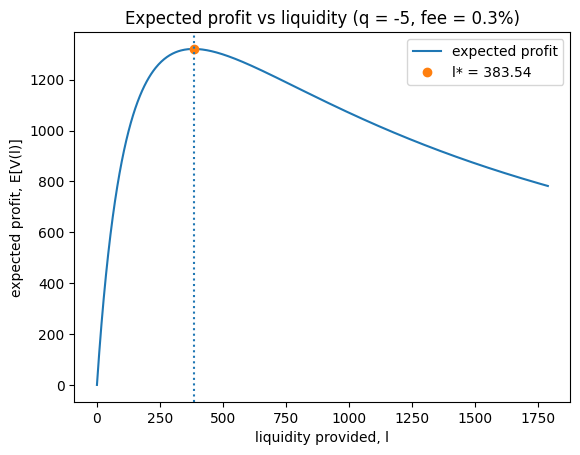

In [52]:
# 4) Plot
l_grid = np.linspace(0, 4*l0, 800)
profit = expected_profit(l_grid)

plt.plot(l_grid, profit, label="expected profit")
plt.plot(l_star, expected_profit(l_star), "o", label=f"l* = {l_star:.2f}")
plt.axvline(l_star, linestyle=":")
plt.xlabel("liquidity provided, l")
plt.ylabel("expected profit, E[V(l)]")
plt.title(f"Expected profit vs liquidity (q = {q}, fee = {(1-gamma)*100:.1f}%)")
plt.legend()
plt.show()

From the last line of the written notes, the FOC can be simplified to the equation

$$
\left[l_0(1-\gamma) - k\left(1 - \gamma + \gamma^2\right)\right]u^2 + 2\gamma k\left[l_0 - (1-\gamma)k\right]u - \gamma^2k^3 = 0
$$

with $k = q\sqrt{P_0}$ and $u = l + l_0$. Using the quadratic formula to solve it,

$$
u = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a},
$$

where

$$
a = l_0(1-\gamma) - k\left(1 - \gamma + \gamma^2\right), \qquad
b = 2\gamma k\left[l_0 - (1-\gamma)k\right], \qquad
c = -\gamma^2k^3,
$$



Since the LP injects liquidity, we need $l > 0$, so we only take the root with $l > 0$.

In [53]:
# 1) coefficients of a u^2 + b u + c = 0  (u = l + l0)
a = l0*(1 - gamma) - q*np.sqrt(P0)*(1 - gamma + gamma**2)
b = 2*gamma*q*np.sqrt(P0)*(l0 - (1 - gamma)*q*np.sqrt(P0))
c = -gamma**2 * (q*np.sqrt(P0))**3

print(f"a = {a:.6f}")
print(f"b = {b:.6f}")
print(f"c = {c:.6f}")

# 2) discriminant
Delta        = b**2 - 4*a*c
print(f"\nDelta (b^2 - 4ac)       = {Delta:.6f}")

# 3) both roots from the quadratic formula
u_plus  = (-b + np.sqrt(Delta))/(2*a)
u_minus = (-b - np.sqrt(Delta))/(2*a)

l_plus  = u_plus - l0
l_minus = u_minus - l0
print(f"\nroot with +: l = {l_plus:.6f}")
print(f"root with -: l = {l_minus:.6f}")

# the LP injects liquidity, so we take the root with l > 0
if l_plus > 0:
    l_quadratic = l_plus
else:
    l_quadratic = l_minus

# 4) Compare bisection and quadratic solution
print(f"\nl* from quadratic formula = {l_quadratic:.10f}")
print(f"l* from bisection         = {l_star:.10f}")
print(f"difference                = {abs(l_quadratic - l_star):.2e}")

a = 224.279631
b = -199699.100000
c = 11113358.471233

Delta (b^2 - 4ac)       = 29909730810.000011

root with +: l = 383.542632
root with -: l = -387.567518

l* from quadratic formula = 383.5426321797
l* from bisection         = 383.5426321797
difference                = 2.39e-11
